In [1]:
"""
code to plot the liveOcean model domain, the bathymetry, and all the data source used
"""

import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import pickle
from cmcrameri import cm
from lo_tools import plotting_functions as pfun
from lo_tools import zfun, Lfun
import matplotlib.colors as mcolors
import matplotlib.patheffects as path_effects
import sys
from pathlib import Path

pth = Path('/b1/yifan/LO_user/pgrid')
if str(pth) not in sys.path:
    sys.path.append(str(pth))


In [2]:
plt.style.use('default')

plt.rcParams.update({
    'axes.labelsize': 18,          # Labels font size
    'xtick.labelsize': 15,         # X-axis ticks font size
    'ytick.labelsize': 15,         # Y-axis ticks font size
    # 'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'out',       # X-axis tick direction
    'ytick.direction': 'out',       # Y-axis tick direction
    'font.size': 15,               # Default font size for other text
})

In [3]:
Ldir = Lfun.Lstart()
gridname = 'cas2k'
pth = Ldir['LOo'] / 'pgrid' /gridname
in_fn = pth/'grid.nc'

fig_dir = Ldir['LOo']/'LO_bias_corr'/'plots'
Lfun.make_dir(fig_dir,clean= False)

# load the data
ds = xr.open_dataset(in_fn)
z = -ds.h.values
mask_rho = ds.mask_rho.values

lon = ds.lon_rho.values
lat = ds.lat_rho.values

plon, plat = pfun.get_plon_plat(lon,lat)
pad = 0.05*(plat[-1,0]-plat[0,0])
pad = 0.0*(plat[-1,0]-plat[0,0])
ax_lims = (plon[0,0]-pad, plon[0,-1]+pad, plat[0,0]-pad, plat[-1,0]+pad)

# make a version of z with nans where masked
zm = z.copy()
zm[mask_rho == 0] = np.nan


In [4]:
bottle = True

WCOA = True # nceicOASTAL
WOD = True
nceiPNW = True
dfo1 = True
HABRISE = True
benthic_OSU = True

df= pd.DataFrame()
if WCOA:    
    year_list = [2007, 2011, 2012, 2013, 2016, 2017, 2021]
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'nceiCoastal'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df
if WOD:    
    year_list = list(np.arange(1993, 2011))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'WOD'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df

if nceiPNW:    
    year_list = list(np.arange(1993, 2009)) + [2010] + list(np.arange(2013, 2018))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'nceiPNW'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df    
if dfo1:
    year_list = list(np.arange(1993, 2022))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'dfo1'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df
if HABRISE:
    year_list = list(np.arange(2003, 2007))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'HABRISE'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df
if benthic_OSU:
    year_list = list(np.arange(2017, 2020))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'benthic_OSU'/'bottle'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        df = pd.concat([df, df0])  # Concatenate df0 into df
ctd = True
HABRISE = False
ocnms = True
iphc = True
Hake = True
dt= pd.DataFrame()
if HABRISE:
    year_list = list(np.arange(2003, 2007))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'HABRISE'/'ctd'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        dt = pd.concat([dt, df0])  # Concatenate df0 into dt
if ocnms:
    year_list = list(np.arange(2004, 2023))
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'OCNMS'/'ctd'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        dt = pd.concat([dt, df0])  # Concatenate df0 into dt
if iphc:
    year_list = list(np.arange(2009, 2019)) + [2021, 2022]
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'IPHC'/'ctd'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        dt = pd.concat([dt, df0])  # Concatenate df0 into dt
if Hake:
    year_list = [2011,  2012, 2013, 2015]
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'Hake'/'ctd'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        dt = pd.concat([dt, df0])  # Concatenate df0 into dt

trawl = True
GroundfishTrawl = True
da= pd.DataFrame()
if GroundfishTrawl:
    year_list = year_list = [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2022]
    for year in year_list:
        in_dir = Ldir['LOo'] / 'obs' /'GroundfishTrawl'/'ctd'
        in_fn = in_dir / ('info_' + str(year) + '.p')
        df0 = pickle.load(open(in_fn, 'rb'))
        da = pd.concat([da, df0])  # Concatenate df0 into ds

fil_dict = dict()  # dict to hold filter choices
# Set mask_salish to True to ignore stations in the Salish Sea
fil_dict['mask_salish'] = True 
if fil_dict['mask_salish']:
    a = df.copy()
    mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124.5)
    mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
    mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
    mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
    mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
    mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
    mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
    a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
    df = a.copy()

    a = dt.copy()
    mask1 = (a.lat >= 46) & (a.lat < 49) & (a.lon > -124.5)
    mask2 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -125)
    mask3 = (a.lat >= 49.5) & (a.lat < 52) & (a.lon > -126)
    mask4 = (a.lat >= 50) & (a.lat < 52) & (a.lon > -128.5)
    mask5 = (a.lat >= 48.5) & (a.lat < 49.5) & (a.lon > -125.5)
    mask6 = (a.lat >= 49) & (a.lat < 51) & (a.lon > -126.5)
    mask7 = (a.lat >= 51) & (a.lat < 52) & (a.lon > -128) & (a.lon < -126.5)
    a = a.loc[(~mask1) & (~mask2) & (~mask3) & (~mask4) & (~mask5) & (~mask6) & (~mask7), :]
    dt = a.copy()


OCNMS_dict = {
    'CA15': [-124.7568, 48.1663],
    'CA42': [-124.8234, 48.1660],
    'CA65': [-124.8949, 48.1659],
    # 'CE15': [-124.3481, 47.3568],
    'CE42': [-124.4887, 47.3531],
    'CE65': [-124.5669, 47.3528],
    # 'KL15': [-124.4284, 47.6008], #no bottom DO
    'KL27': [-124.4971, 47.5946],   
    # 'MB15': [-124.6768, 48.3254], #no bottom DO
    'MB42': [-124.7354, 48.3240],
    # 'TH15': [-124.619467, 47.876117], # too short
    'TH42': [-124.733417, 47.875817],
}



LineP_dict = {

    'P01': [-125.5000, 48.5750],  # 120 m
    'P02': [-126.0000, 48.6000],  # 114 m
    'P03': [-126.3333, 48.6250],  # 750 m
    'P04': [-126.6667, 48.6500],  # 1300 m
    'P05': [-127.1667, 48.6917],  # 2100 m
    'P06': [-127.6667, 48.7433],  # 2500 m
    'P07': [-128.1667, 48.7767],  # 2450 m
    'P08': [-128.6667, 48.8167],  # 2440 m
    'P09': [-129.1667, 48.8567],  # 2340 m
    'P10': [-129.6667, 48.8933],  # 2660 m
    #'P11': [-130.1667, 48.9333],  # 2700 m
    #'P12': [-130.6667, 48.9700]  # 3300 m # this is out of model domain
}

P4_dict = {

    'P04': [-126.6667, 48.6500],  # 1300 m

}

# Newport Hydrography Line
NHL_dict = {
    'NH01': [-124.100, 44.652],  # 30 m
    'NH03': [-124.130, 44.652],  # 48 m
    'NH05': [-124.177, 44.652],  # 60 m
    'NH10': [-124.295, 44.652],  # 81 m
    'NH15': [-124.412, 44.652],  # 90 m
    'NH20': [-124.528, 44.652],  # 140 m
    'NH25': [-124.650, 44.652],  # 296 m
    'NH35': [-124.880, 44.652],  # 452 m
    'NH45': [-125.120, 44.652],  # 500 m
    'NH65': [-125.600, 44.652],  # 1000 m

}



/tmp/ipykernel_3836148/2649580827.py:16: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  df0 = pickle.load(open(in_fn, 'rb'))
/tmp/ipykernel_3836148/2649580827.py:16: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If 

In [5]:
# add LMEs
import geopandas as gpd
shp_fn = Ldir['data']/'eiwg_boundary_2023/eiwg_boundaries_20230512.shp'
gdf = gpd.read_file(shp_fn)
ccs = gdf.iloc[[3]]
print(gdf)
print(gdf.columns)

        area_km2                     RegionName  \
0   2.333830e+05                 U.S. Caribbean   
1   6.523720e+06                Pacific Islands   
2   9.102636e+05                 Gulf of Mexico   
3   1.379538e+06             California Current   
4   3.571463e+06  Chukchi and North Bering Seas   
5   7.963130e+05                 Northeast U.S.   
6   3.362559e+06                 Gulf of Alaska   
7   1.698810e+06               Aleutian Islands   
8   2.602892e+06                   Beaufort Sea   
9   4.669218e+06                East Bering Sea   
10  5.909045e+05                 Southeast U.S.   
11  3.616969e+04                   Lake Ontario   
12  1.124349e+05                  Lake Michigan   
13  1.282779e+05                     Lake Huron   
14  4.649504e+04                      Lake Erie   
15  1.832264e+05                  Lake Superior   

                                             geometry  
0   POLYGON ((-66.66195 21.84095, -66.65406 21.840...  
1   MULTIPOLYGON (((

In [6]:
source_list = ['P4','OCNMS', 'NHL', 'LineP']
color = ['#FF00FF','g','b','#FF00FF']
marker =['s','*', '-o','-^']


/tmp/ipykernel_3836148/1540134287.py:36: UserWarning: You passed a edgecolor/edgecolors ('#FC6C85') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(da['lon'], da['lat'], c='#7B5A8E', marker= '+', s=5, edgecolors='#FC6C85', linewidths=0.5, label= 'Trawl')


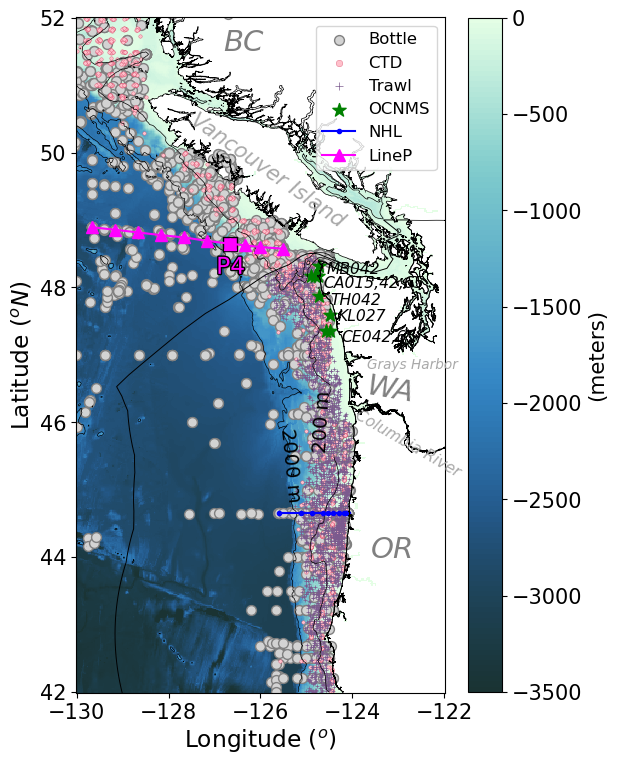

In [7]:
small = True

# PLOTTING
plt.close('all')
fs = 14
if small:
    figsize = (6,8)
else:
    figsize = (12,12)
pfun.start_plot(figsize=figsize)

cmap = cm.bukavu
fraction = 0.4999
n_colors = int(fraction * cmap.N)  # Number of colors to keep
new_colors = cmap(np.linspace(0, fraction, n_colors))  # Select the colors
# Create the new colormap
new_cmap = mcolors.ListedColormap(new_colors)
# bathymetry
fig = plt.figure()
ax = fig.add_subplot(111)
# cs = ax.pcolormesh(plon, plat, zm, vmin=zmin, vmax=0, cmap='Blues_r') # 'gist_earth'

cs = ax.pcolormesh(plon, plat, zm, vmin=-3500, vmax=0, cmap=new_cmap)
pfun.add_bathy_contours(ax, ds, txt=True)

cbar = fig.colorbar(cs, ax=ax,shrink=0.98)
cbar.set_label(label='(meters)', fontsize=fs*1.1)
# Add data sources
if bottle:
    ax.scatter(df['lon'], df['lat'], c='lightgray', marker= 'o', s=50, edgecolors='gray', linewidths=1, label= 'Bottle')

if ctd:
    ax.scatter(dt['lon'], dt['lat'], c='pink', marker= '.', s=25, edgecolors='#D94A6A', linewidths=0.25, label= 'CTD')

if trawl:
    ax.scatter(da['lon'], da['lat'], c='#7B5A8E', marker= '+', s=5, edgecolors='#FC6C85', linewidths=0.5, label= 'Trawl')
ii = 0
for source in source_list:    
    source_dict = globals().get(f'{source}_dict')    
    if source_dict:  # Check if the dictionary exists
        loc = list(source_dict.values())  # Extract coordinates
        sn_list = list(source_dict.keys())  # Extract station names
        lon, lat = zip(*loc)  # Separate longitude and latitude
        lon = np.array(lon)
        lat = np.array(lat)
    if source == 'LineP':
        ax.plot(lon, lat, marker[ii], color=color[ii], markersize=8,
                markeredgecolor=color[ii], markeredgewidth=1, label=source)
        
    elif  source == 'NHL':        
        ax.plot(lon, lat, marker[ii], color=color[ii], markersize=3,
                markeredgecolor=color[ii], markeredgewidth=1, label=source)
        
    elif source == 'P4':
        ax.scatter(lon, lat, c=color[ii], marker= marker[ii], s=110, edgecolors='k', linewidths=1, label= '')
        text = ax.text(.38, .62, 'P4', fontsize = fs*1.2, color = '#FF00FF',  transform=ax.transAxes)        
        text.set_path_effects([path_effects.Stroke(linewidth=2, foreground='black'), path_effects.Normal()])
    else:
        ax.scatter(lon, lat, c=color[ii], marker= marker[ii], s=100, edgecolors=color[ii], linewidths=1, label=source)
    ii += 1

leg = ax.legend(loc='upper right', fontsize=fs*0.85)
# 0 Bottle, 1 CTD, 2 Trawl, 3 OCNMS, 4 NHL, 5 LineP
leg.legend_handles[1].set_sizes([90])   # CTD
leg.legend_handles[2].set_sizes([40])   # Trawl

# add CCS LME boundary
ccs.boundary.plot(
    ax=ax,
    color='black',
    linewidth=0.7,
    linestyle='-',
    zorder=10
)
ax.text(.8, .2, 'OR', fontsize=fs*1.5, color='gray', fontstyle='italic', transform=ax.transAxes)
ax.text(.78, .43, 'WA', fontsize = fs*1.5, color = 'gray',  fontstyle='italic', transform=ax.transAxes, rotation=-10)
ax.text(.4, .95, 'BC', fontsize = fs*1.5, color = 'gray',  fontstyle='italic', transform=ax.transAxes)
ax.text(.79, .48, 'Grays Harbor', fontsize = fs*0.7, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes)
ax.text(.3, .69, 'Vancouver Island', fontsize = fs*1.1, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=-35)
ax.text(.75, .32, 'Columbia River', fontsize = fs*0.8, color = 'darkgray',  fontstyle='italic', transform=ax.transAxes, rotation=-30)

ax.text(.68, .62, 'MB042', fontsize = fs*0.8, color = 'black',  fontstyle='italic', transform=ax.transAxes)
ax.text(.67, .60, 'CA015,42,65', fontsize = fs*0.8, color = 'black',  fontstyle='italic', transform=ax.transAxes)
ax.text(.69, .575, 'TH042', fontsize = fs*0.8, color = 'black',  fontstyle='italic', transform=ax.transAxes)
ax.text(.71, .55, 'KL027', fontsize = fs*0.8, color = 'black',  fontstyle='italic', transform=ax.transAxes)
ax.text(.72, .52, 'CE042,65', fontsize = fs*0.8, color = 'black',  fontstyle='italic', transform=ax.transAxes)


ax.axis(ax_lims)

ax.set_xlabel('Longitude ($^{o}$)', fontsize=fs*1.2)
ax.set_ylabel('Latitude ($^{o}N$)', fontsize=fs*1.2)
ax.grid(False)

pfun.add_coast(ax)
pfun.dar(ax)
# plt.subplots_adjust(left=0.17, right=0.98, top=0.98, bottom=0.05)
plt.tight_layout()
fig.savefig(fig_dir/f'{gridname}_grid_map_Figure_01.png', bbox_inches='tight', dpi = 300)
plt.show()